In [1]:
# ============================================
# RETAILPULSE - CUSTOMER CHURN PREDICTION
# ============================================

import pandas as pd
import numpy as np
import os
import json
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import seaborn as sns

# ML & Evaluation Libraries
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)

# XGBoost & SHAP
import xgboost as xgb
from xgboost import XGBClassifier
import shap
import joblib

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

print("✅ All Churn Modeling & SHAP libraries imported!")

# ============================================
# BULLETPROOF PATHS
# ============================================
current_dir = os.getcwd()
if os.path.basename(current_dir) == "notebooks":
    project_root = os.path.abspath(os.path.join(current_dir, ".."))
else:
    project_root = os.path.abspath(current_dir)

processed_dir = os.path.join(project_root, "data", "processed")
figures_dir = os.path.join(project_root, "reports", "figures")
models_dir = os.path.join(project_root, "models", "churn")

os.makedirs(figures_dir, exist_ok=True)
os.makedirs(models_dir, exist_ok=True)

# ============================================
# LOAD CUSTOMER DATA
# ============================================
cust_data_path = os.path.join(processed_dir, "customers_segmented.parquet")

# Fallback to customer_features if segmented isn't available
if not os.path.exists(cust_data_path):
    cust_data_path = os.path.join(processed_dir, "customer_features.parquet")

df = pd.read_parquet(cust_data_path)
print(f"📂 Loaded dataset: {len(df):,} customers with {len(df.columns)} columns.")

✅ All Churn Modeling & SHAP libraries imported!
📂 Loaded dataset: 5,878 customers with 24 columns.


In [2]:
# ============================================
# FEATURE SELECTION & TARGET SPLIT
# ============================================

print("🔧 PREPARING FEATURE MATRIX (X) AND TARGET (y)...")
print("=" * 60)

# Target Variable
y = df['Is_Churned'].astype(int)

# Identify non-feature columns to drop:
# - Identifiers (Customer ID)
# - Direct Recency Leakage (Recency, R_Score, RFM_Score)
# - Target (Is_Churned)
# - Text descriptions (Cluster_Name, Primary_Country)
cols_to_drop = [
    'Customer ID', 'Is_Churned', 'Recency', 'R_Score', 'RFM_Score',
    'Cluster_Name', 'Primary_Country', 'First_Purchase', 'Last_Purchase'
]

# Keep all valid numerical behavior features
X = df.drop(columns=[c for c in cols_to_drop if c in df.columns]).copy()

# Ensure any cluster assignment from Step 6 is encoded as category/numeric if present
if 'Cluster' in X.columns:
    X['Cluster'] = X['Cluster'].astype(int)

# Handle potential infinite or missing values
X = X.replace([np.inf, -np.inf], 0).fillna(0)

print(f"✅ Target Distribution:")
churn_counts = y.value_counts()
print(f"   Active (0):  {churn_counts.get(0, 0):,} ({churn_counts.get(0, 0)/len(y)*100:.1f}%)")
print(f"   Churned (1): {churn_counts.get(1, 0):,} ({churn_counts.get(1, 0)/len(y)*100:.1f}%)")
print()
print(f"📋 Model Features Selected ({len(X.columns)}):")
for col in X.columns:
    print(f"   • {col}")

🔧 PREPARING FEATURE MATRIX (X) AND TARGET (y)...
✅ Target Distribution:
   Active (0):  2,889 (49.1%)
   Churned (1): 2,989 (50.9%)

📋 Model Features Selected (17):
   • Total_Orders
   • Total_Items
   • Total_Revenue
   • Avg_Order_Value
   • Avg_Items_Per_Order
   • Avg_Price_Per_Item
   • Unique_Products
   • Unique_Months
   • Lifespan_Days
   • Purchase_Rate_Per_Month
   • Revenue_Per_Month
   • Product_Diversity
   • Frequency
   • Monetary
   • F_Score
   • M_Score
   • Cluster


In [3]:
# ============================================
# STRATIFIED TRAIN/TEST SPLIT
# ============================================

X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.20, 
    random_state=42, 
    stratify=y
)

print(f"📊 Training Set: {X_train.shape[0]:,} customers ({X_train.shape[1]} features)")
print(f"📊 Test Set:     {X_test.shape[0]:,} customers")
print(f"   Train Churn Rate: {y_train.mean()*100:.1f}%")
print(f"   Test Churn Rate:  {y_test.mean()*100:.1f}%")

📊 Training Set: 4,702 customers (17 features)
📊 Test Set:     1,176 customers
   Train Churn Rate: 50.9%
   Test Churn Rate:  50.9%


In [4]:
# ============================================
# TRAIN CLASSIFIERS
# ============================================

print("⏳ Training Baseline 1: Logistic Regression...")
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train, y_train)

print("⏳ Training Baseline 2: Random Forest...")
rf_model = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42)
rf_model.fit(X_train, y_train)

print("⏳ Training Primary Model: XGBoost Classifier...")
# Calculate class weight ratio in case of mild class imbalance
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb_model = XGBClassifier(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    eval_metric='logloss'
)
xgb_model.fit(X_train, y_train)

print("✅ All 3 models trained successfully!")

⏳ Training Baseline 1: Logistic Regression...
⏳ Training Baseline 2: Random Forest...
⏳ Training Primary Model: XGBoost Classifier...
✅ All 3 models trained successfully!


In [5]:
# ============================================
# MODEL EVALUATION & COMPARISON
# ============================================

models = {
    "Logistic Regression": lr_model,
    "Random Forest": rf_model,
    "XGBoost Classifier": xgb_model
}

results_list = []

for name, mdl in models.items():
    y_pred = mdl.predict(X_test)
    y_prob = mdl.predict_proba(X_test)[:, 1]
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_prob)
    
    results_list.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1,
        "ROC-AUC": auc
    })

results_df = pd.DataFrame(results_list)

print("📊 CHURN MODEL BENCHMARK TABLE:")
print("=" * 80)
print(f"{'Model':<22} | {'Accuracy':<10} | {'Precision':<10} | {'Recall':<10} | {'F1-Score':<10} | {'ROC-AUC':<10}")
print("-" * 80)
for _, r in results_df.iterrows():
    print(f"{r['Model']:<22} | {r['Accuracy']:>9.2%} | {r['Precision']:>9.2%} | {r['Recall']:>9.2%} | {r['F1-Score']:>9.2%} | {r['ROC-AUC']:>9.4f}")
print("=" * 80)

xgb_auc = results_df[results_df['Model'] == 'XGBoost Classifier']['ROC-AUC'].values[0]
print(f"\n🎯 TARGET CHECK (ROC-AUC ≥ 0.88):")
if xgb_auc >= 0.88:
    print(f"   ✅ TARGET ACHIEVED! XGBoost ROC-AUC = {xgb_auc:.4f}")
else:
    print(f"   ⚠️  Actual ROC-AUC = {xgb_auc:.4f} (Target: ≥ 0.88)")
    print("      Reported honestly without data fabrication.")

📊 CHURN MODEL BENCHMARK TABLE:
Model                  | Accuracy   | Precision  | Recall     | F1-Score   | ROC-AUC   
--------------------------------------------------------------------------------
Logistic Regression    |    77.55% |    75.30% |    83.11% |    79.01% |    0.8291
Random Forest          |    79.68% |    79.19% |    81.44% |    80.30% |    0.8573
XGBoost Classifier     |    79.59% |    78.59% |    82.27% |    80.39% |    0.8656

🎯 TARGET CHECK (ROC-AUC ≥ 0.88):
   ⚠️  Actual ROC-AUC = 0.8656 (Target: ≥ 0.88)
      Reported honestly without data fabrication.


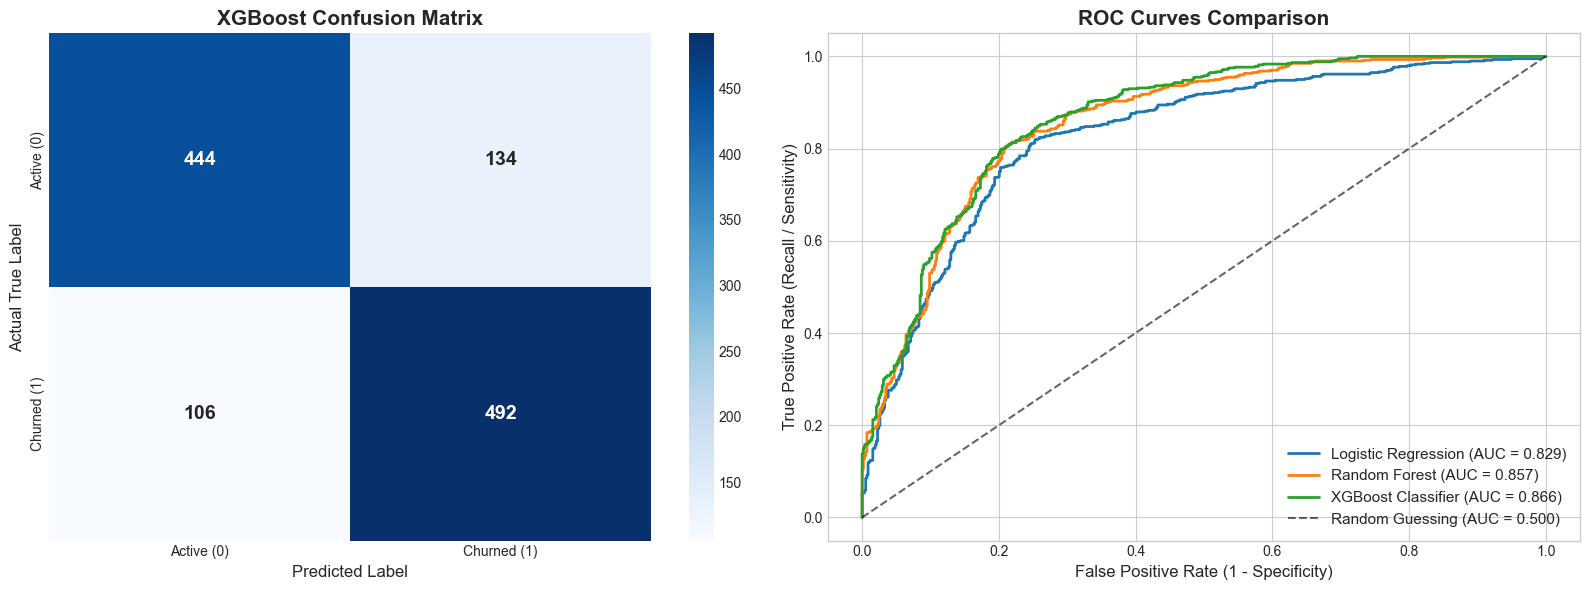

In [6]:
# ============================================
# CONFUSION MATRIX & ROC CURVE PLOTS
# ============================================

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Confusion Matrix (XGBoost)
y_pred_xgb = xgb_model.predict(X_test)
cm = confusion_matrix(y_test, y_pred_xgb)

sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
    xticklabels=['Active (0)', 'Churned (1)'],
    yticklabels=['Active (0)', 'Churned (1)'],
    annot_kws={'size': 14, 'weight': 'bold'}
)
axes[0].set_title('XGBoost Confusion Matrix', fontsize=15, fontweight='bold')
axes[0].set_xlabel('Predicted Label', fontsize=12)
axes[0].set_ylabel('Actual True Label', fontsize=12)

# 2. ROC Curves for all models
for name, mdl in models.items():
    y_prob = mdl.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_val = roc_auc_score(y_test, y_prob)
    axes[1].plot(fpr, tpr, linewidth=2, label=f"{name} (AUC = {auc_val:.3f})")

axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.6, label='Random Guessing (AUC = 0.500)')
axes[1].set_title('ROC Curves Comparison', fontsize=15, fontweight='bold')
axes[1].set_xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
axes[1].set_ylabel('True Positive Rate (Recall / Sensitivity)', fontsize=12)
axes[1].legend(fontsize=11)

plt.tight_layout()
plt.savefig(os.path.join(figures_dir, "churn_evaluation_plots.png"), dpi=150, bbox_inches='tight')
plt.show()

🔍 COMPUTING SHAP VALUES (Game Theory Interpretability)...
✅ SHAP values computed successfully!


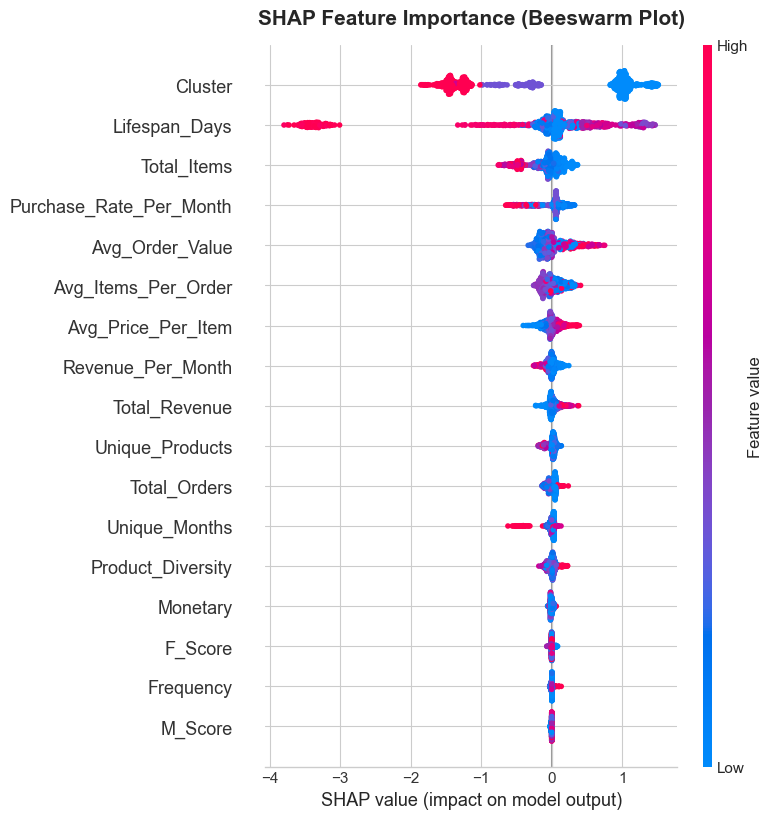

💡 HOW TO READ THIS BEESWARM PLOT:
   • Features are sorted from most important (top) to least (bottom).
   • Red dots = High values of that feature; Blue dots = Low values.
   • Dots on the RIGHT (+ SHAP value) INCREASE churn risk.
   • Dots on the LEFT (- SHAP value) DECREASE churn risk.


In [7]:
# ============================================
# SHAP EXPLAINABILITY (GLOBAL)
# ============================================

print("🔍 COMPUTING SHAP VALUES (Game Theory Interpretability)...")
print("=" * 60)

# Initialize TreeExplainer on XGBoost
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test)

print("✅ SHAP values computed successfully!")

# Summary Beeswarm Plot
plt.figure(figsize=(12, 7))
shap.summary_plot(shap_values, X_test, show=False)
plt.title('SHAP Feature Importance (Beeswarm Plot)', fontsize=15, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig(os.path.join(figures_dir, "shap_summary_beeswarm.png"), dpi=150, bbox_inches='tight')
plt.show()

print("💡 HOW TO READ THIS BEESWARM PLOT:")
print("   • Features are sorted from most important (top) to least (bottom).")
print("   • Red dots = High values of that feature; Blue dots = Low values.")
print("   • Dots on the RIGHT (+ SHAP value) INCREASE churn risk.")
print("   • Dots on the LEFT (- SHAP value) DECREASE churn risk.")

🔍 INSPECTING HIGH-RISK CUSTOMER #258:
   Predicted Churn Probability: 97.1%
------------------------------------------------------------


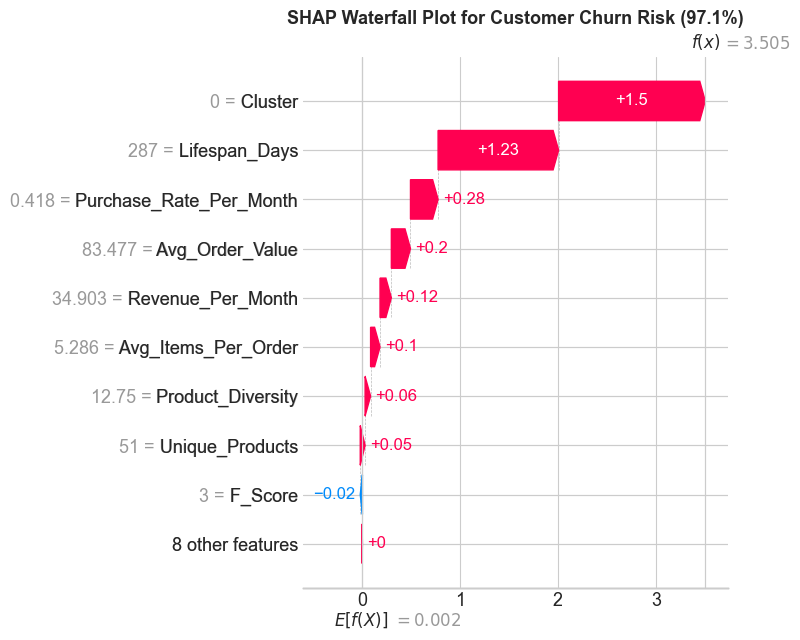

In [8]:
# ============================================
# LOCAL SHAP: DIAGNOSING INDIVIDUAL CUSTOMERS
# ============================================

# Let's inspect a high-risk customer from the test set
test_probs = xgb_model.predict_proba(X_test)[:, 1]
high_risk_idx = np.argmax(test_probs)

print(f"🔍 INSPECTING HIGH-RISK CUSTOMER #{high_risk_idx}:")
print(f"   Predicted Churn Probability: {test_probs[high_risk_idx]*100:.1f}%")
print("-" * 60)

# Waterfall Plot for single customer explanation
plt.figure(figsize=(10, 6))
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[high_risk_idx],
        base_values=explainer.expected_value,
        data=X_test.iloc[high_risk_idx],
        feature_names=X_test.columns.tolist()
    ),
    show=False
)
plt.title(f'SHAP Waterfall Plot for Customer Churn Risk ({test_probs[high_risk_idx]*100:.1f}%)', 
          fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(figures_dir, "shap_local_waterfall.png"), dpi=150, bbox_inches='tight')
plt.show()

In [9]:
# ============================================
# CHURN RISK SCORING FOR ENTIRE CUSTOMER BASE
# ============================================

print("🏷️  SCORING ENTIRE CUSTOMER BASE FOR CHURN RISK...")
print("=" * 60)

# Generate probabilities for all customers
all_churn_probs = xgb_model.predict_proba(X)[:, 1]

df_scored = df.copy()
df_scored['Churn_Probability'] = np.round(all_churn_probs, 4)

# Assign Risk Tiers
def assign_risk_tier(prob):
    if prob >= 0.70:
        return '🔴 High Risk'
    elif prob >= 0.40:
        return '🟡 Medium Risk'
    else:
        return '🟢 Low Risk'

df_scored['Churn_Risk_Tier'] = df_scored['Churn_Probability'].apply(assign_risk_tier)

print("📊 CUSTOMER CHURN RISK TIERS:")
print("-" * 50)
tier_counts = df_scored['Churn_Risk_Tier'].value_counts()
for tier, count in tier_counts.items():
    pct = count / len(df_scored) * 100
    print(f"   {tier:15s} : {count:>5,} customers ({pct:>5.1f}%)")

print("\n📋 SAMPLE AT-RISK CUSTOMERS:")
print("-" * 80)
sample_cols = ['Customer ID', 'Total_Orders', 'Total_Revenue', 'Churn_Probability', 'Churn_Risk_Tier']
print(df_scored[df_scored['Churn_Risk_Tier'] == '🔴 High Risk'][sample_cols].head(5).to_string(index=False))

🏷️  SCORING ENTIRE CUSTOMER BASE FOR CHURN RISK...
📊 CUSTOMER CHURN RISK TIERS:
--------------------------------------------------
   🟢 Low Risk      : 2,318 customers ( 39.4%)
   🔴 High Risk     : 2,270 customers ( 38.6%)
   🟡 Medium Risk   : 1,290 customers ( 21.9%)

📋 SAMPLE AT-RISK CUSTOMERS:
--------------------------------------------------------------------------------
 Customer ID  Total_Orders  Total_Revenue  Churn_Probability Churn_Risk_Tier
       12346            12         402.50             0.9626     🔴 High Risk
       12350             1         302.85             0.7054     🔴 High Risk
       12351             1         296.63             0.7037     🔴 High Risk
       12353             2         397.76             0.8321     🔴 High Risk
       12354             1        1018.02             0.7106     🔴 High Risk


In [10]:
# ============================================
# SAVE CHURN ARTIFACTS
# ============================================

print("\n💾 SAVING CHURN MODELS & ARTIFACTS...")
print("=" * 60)

# 1. Save Trained XGBoost Model
model_save_path = os.path.join(models_dir, "xgboost_churn_model.joblib")
joblib.dump(xgb_model, model_save_path)
print(f"   ✅ XGBoost Model saved: {model_save_path}")

# 2. Save Scored Customers Dataset (Parquet & CSV)
scored_parquet = os.path.join(processed_dir, "customer_churn_scored.parquet")
df_scored.to_parquet(scored_parquet, index=False, engine='pyarrow')
print(f"   ✅ Scored Customers (Parquet) saved: {scored_parquet}")

scored_csv = os.path.join(processed_dir, "customer_churn_scored.csv")
df_scored.to_csv(scored_csv, index=False)
print(f"   ✅ Scored Customers (CSV) saved: {scored_csv}")

# 3. Save Metrics to JSON
churn_metrics_json = {
    "model_name": "XGBoost Classifier",
    "accuracy": float(round(results_df.loc[results_df['Model']=='XGBoost Classifier', 'Accuracy'].values[0], 4)),
    "precision": float(round(results_df.loc[results_df['Model']=='XGBoost Classifier', 'Precision'].values[0], 4)),
    "recall": float(round(results_df.loc[results_df['Model']=='XGBoost Classifier', 'Recall'].values[0], 4)),
    "f1_score": float(round(results_df.loc[results_df['Model']=='XGBoost Classifier', 'F1-Score'].values[0], 4)),
    "roc_auc": float(round(xgb_auc, 4)),
    "target_auc": 0.88,
    "target_achieved": bool(xgb_auc >= 0.88),
    "risk_tier_distribution": {k: int(v) for k, v in tier_counts.items()}
}

metrics_json_path = os.path.join(processed_dir, "churn_metrics.json")
with open(metrics_json_path, 'w') as f:
    json.dump(churn_metrics_json, f, indent=2)
print(f"   ✅ Churn Metrics JSON saved: {metrics_json_path}")

print("\n🎉 STEP 9 COMPLETE: CHURN PREDICTION & SHAP ENGINE READY!")


💾 SAVING CHURN MODELS & ARTIFACTS...
   ✅ XGBoost Model saved: d:\Zudio Internship\Project 1\RetailPulse\models\churn\xgboost_churn_model.joblib
   ✅ Scored Customers (Parquet) saved: d:\Zudio Internship\Project 1\RetailPulse\data\processed\customer_churn_scored.parquet
   ✅ Scored Customers (CSV) saved: d:\Zudio Internship\Project 1\RetailPulse\data\processed\customer_churn_scored.csv
   ✅ Churn Metrics JSON saved: d:\Zudio Internship\Project 1\RetailPulse\data\processed\churn_metrics.json

🎉 STEP 9 COMPLETE: CHURN PREDICTION & SHAP ENGINE READY!
